# Freezer temperature test

Restart an existing kernel once to load the updated Python client. Use the workspace .venv kernel.
Run through **Setup and start cooldown**, then **Live dashboard**.
Setup deliberately replaces current operations with low power and prints status for your visual check.
Choose later phases by changing their action flags and running their cells individually.

The poll thread continues during other cells, including blocking pcb calls. Widget redraws wait for the
kernel loop, so a busy cell can delay the display without stopping acquisition. Messages go to the .log
file; the .pkl capture is replaced atomically after each poll. Closing/pausing the plot does not stop logging.

A driver's TEC probe approximates its idle driver/bank temperature with the TEC off, and measures
regulated diode temperature with the TEC running. The default load leaves 1430hk and its TEC idle
as a box probe. The heater's idle average excludes running TECs; it is an aggregate, not another sensor.
The existing temps command reads an already-powered bank without enabling power. Disable
READ_INDIVIDUAL_TEMPS below if you want only cached heater temperatures.

PDs use explicit override modes so readback does not auto-enable them. Override-on cancels PD
auto-off; use **Return to low power** when desired. **Stop and save** only ends local acquisition.

Heater overrides force the relay but continue temperature observation while the bank is powered.
They do not enable bank power. Cached heater probes age out after 20 s without valid updates.

Low power uses each laser endpoint to stop output, preserves bank power/mode, and restores heater auto.
TEC shutdown follows each channel's disable_tec_at_autooff policy; inspect the result table for errors.


In [178]:
%matplotlib widget
from pathlib import Path
from dataclasses import asdict
from datetime import datetime, timezone
from functools import partial
from html import escape
import asyncio
import logging
import sys
import threading
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

TOOLS = next(p.resolve() for p in (Path.cwd(), Path.cwd() / 'tools', Path.cwd() / 'hispec-tib/tools') if (p / 'hispec_fibpcb.py').is_file())
if str(TOOLS) not in sys.path:
    sys.path.insert(0, str(TOOLS))
import hispec_fibpcb as hspcb
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.18})


In [179]:
BROKER, DEVICE = 'hispec.caltech.edu', 'hsfib-tib'
DATA_DIR = TOOLS / 'temp_data'
PATCH_NOTES = 'B AO->3dB->FFLC MM Yellow(B)'  # Add freezer placement / operator notes here.
READ_INDIVIDUAL_TEMPS = True
TEMP_POLL_INTERVAL_S = 10.
PLOT_REFRESH_INTERVAL_S = 180.
TEMP_COLUMNS = ['issue_utc_ms', 'receipt_utc_ms', 'elapsed_s', 'phase', 'poll_interval_s',
    *hspcb.LaserBankHeater.__dataclass_fields__, 'bank_mode', 'bank_powered',
    'heater_receipt_utc_ms', 'temps_receipt_utc_ms',
    *[f'probe_{name}_c' for name in hspcb.LASER_NAMES],
    *[f'pd_{channel}_{field}' for channel in hspcb.PD_CHANNELS for field in ('mode', 'powered', 'on_s')], 'error']


## Capture helpers

These cells define acquisition, saving, and the explicit low-power operation; they do not contact hardware.
Host issue/receipt times are retained alongside board ACK times. Plot command lines use **host issue UTC**,
which shares the sample clock; ACKs are not mixed into that axis or treated as settling times.


In [180]:
def checkpoint_temp(run):
    """Save raw tables under a lock; replace only this run's exclusively reserved file."""
    with run['lock']:
        saved = dict(samples=run['samples'].copy(), events=pd.DataFrame(run['events']),
            darks=pd.DataFrame(run['darks']), context=run['context'].copy(), outcome=run['outcome'].copy())
        temporary = run['path'].with_suffix('.pkl.tmp')
        pd.to_pickle(saved, temporary)
        temporary.replace(run['path'])
        run['saved_utc_ms'] = time.time_ns() // 1_000_000


def status_snapshot(run):
    """Read cached board status or record the query error without gating acquisition."""
    try: return asdict(run["client"].status())
    except Exception as exc: return dict(error=str(exc))


def apply_low_power(run):
    """Explicit low power: stop operations/lasers, zero FVOAs, PDs off and heater auto.

    Keep bank power/mode unchanged; respect each laser's disable_tec_at_autooff setting.
    Restore heater auto every time; heater-mode commands persist their policy in firmware.
    Other settings/calibration are not persisted here. Continue after errors and display every result.
    """
    client = run['client']
    run['phase'] = 'low_power'
    operations = [('throughput stop', partial(client.stop_throughput, 'all')),
        ('calibration stop', client.atten_calibrate_stop),
        *[(f'{name} laser stop', partial(client.laser, name, stop=True)) for name in hspcb.LASER_NAMES],
        *[(f'{n} FVOAs zero', partial(client.atten, n, value1_mv=0, value2_mv=0)) for n in hspcb.LASER_NAMES],
        *[(f'{c} PD off', partial(client.pd_settings, c, power='override_off', persist=False)) for c in hspcb.PD_CHANNELS],
        ('heater auto', partial(client.laser_bankheater, 'auto'))]
    results = []
    for operation, call in operations:
        try: results.append(dict(operation=operation, ok=True, result=asdict(call()), error=''))
        except Exception as exc: results.append(dict(operation=operation, ok=False, result=None, error=str(exc)))
    return pd.DataFrame(results)


def stop_temp_capture(run):
    """Stop/join local polling and save final cached status; never switch loads off."""
    run['stop'].set()
    if run.get('thread') is not None:
        run['thread'].join(timeout=max(2., 8 * run['client'].timeout_s))
        if run['thread'].is_alive():
            raise RuntimeError('Poll still finishing; rerun stop before starting another capture.')
    if run.get('plot_task') is not None: run['plot_task'].cancel()
    try:
        if run['outcome']['running']:
            sample_temperature(run)
            run['context']['final_status'] = status_snapshot(run)
        run['outcome'].update(running=False, stopped_utc_ms=time.time_ns() // 1_000_000)
        checkpoint_temp(run)
    finally:
        run['client'].on_command = run['previous_callback']
        run['client'].logger = run['previous_logger']
        run['logger'].removeHandler(run['handler'])
        run['handler'].close()
    return run['path']


In [181]:
def sample_temperature(run):
    """Read existing telemetry only; skip temps while bank off and PD readback in auto mode.

    These are sequential cached/query observations, not simultaneous sensor conversions. Errors leave
    missing values, while heater poll age makes its cache age visible. No power/timer writes occur here.
    """
    client = run['client']
    row = dict(issue_utc_ms=time.time_ns() // 1_000_000, phase=run['phase'],
        poll_interval_s=max(.1, float(TEMP_POLL_INTERVAL_S)))
    errors = []
    def read(label, call, *args):
        try:
            value = call(*args)
            row[f'{label}_receipt_utc_ms'] = time.time_ns() // 1_000_000
            return value
        except Exception as exc:
            errors.append(f'{label}: {type(exc).__name__}: {exc}')
    heater = read('heater', client.laser_bankheater)
    if heater is not None: row.update(asdict(heater))
    bank = read('bank', client.laser_bankpower)
    if bank is not None: row.update(bank_mode=bank.mode, bank_powered=bank.powered)
    # temps -> hispec_laser_bank_read_temperatures has no ensure-bank-powered call.
    if READ_INDIVIDUAL_TEMPS and bank is not None and bank.powered:
        temperatures = read('temps', client.temps)
        if temperatures is not None:
            row.update({f'probe_{v.name}_c': v.value for v in temperatures.lasers})
    for channel in hspcb.PD_CHANNELS:
        settings = read(f'pd_{channel}_settings', client.pd_settings, channel)
        if settings is not None:
            row[f'pd_{channel}_mode'] = settings.power
            if settings.power in ('override_on', 'override_off'):
                values = read(f'pd_{channel}', client.pd, channel)
                if values is not None:
                    state = getattr(values, channel)
                    row.update({f'pd_{channel}_powered': state.pd_powered, f'pd_{channel}_on_s': state.pd_on_s})
    row.update(receipt_utc_ms=time.time_ns() // 1_000_000,
        elapsed_s=time.monotonic() - run['start_monotonic'], error='; '.join(errors))
    if errors: run['logger'].warning('Poll: %s', row['error'])
    with run['lock']:
        run['samples'].loc[len(run['samples'])] = [row.get(name, np.nan) for name in TEMP_COLUMNS]
    return row


def poll_temperature(run):
    """One lab worker: collect and checkpoint independently of the notebook kernel loop."""
    previous = time.monotonic()
    while not run['stop'].wait(min(.25, max(.1, float(TEMP_POLL_INTERVAL_S))/4)):
        if time.monotonic() - previous < max(.1, float(TEMP_POLL_INTERVAL_S)): continue
        previous = time.monotonic()
        try:
            sample_temperature(run)
            run['outcome']['poll_error'] = ''
            checkpoint_temp(run)
        except Exception as exc:
            run['outcome']['poll_error'] = str(exc)
            run['logger'].exception('Poll/checkpoint failed; retaining in-memory data for next checkpoint')


In [182]:
def draw_temperature_plot(run):
    """Draw only on the kernel loop; shade sampled heater state and mark host command issue times."""
    with run['lock']:
        frame, events = run['samples'].copy(), list(run['events'])
    if frame.empty: return
    axes = run['axes']
    for ax in axes: ax.clear()
    hours = (frame.receipt_utc_ms - run['start_utc_ms']) / 3_600_000
    gaps = frame.elapsed_s.diff().gt(1.5 * frame.poll_interval_s) | hours.diff().le(0)
    temperatures = dict(ambient_c='Ambient', idle_tec_avg_c='Idle TEC average',
        **{f'probe_{n}_c': f'{n} TEC probe' for n in hspcb.LASER_NAMES})
    for column, label in temperatures.items():
        axes[0].plot(hours, pd.to_numeric(frame[column], errors='coerce').mask(gaps), label=label)
    fresh = frame.poll_age_s.notna() & frame.poll_age_s.le(20)
    for i in range(len(frame)-1):
        if frame.heater_on.iloc[i] == True and fresh.iloc[i] and not gaps.iloc[i+1]:
            axes[0].axvspan(hours.iloc[i], hours.iloc[i+1], color='tab:orange', alpha=.12, lw=0)
    stale = ~fresh
    axes[0].scatter(hours[stale], pd.to_numeric(frame.idle_tec_avg_c, errors='coerce')[stale], marker='x', color='red', label='stale heater cache')
    for i, column in enumerate(('heater_on', 'bank_powered', 'pd_yj_powered', 'pd_hk_powered')):
        axes[1].step(hours, i + .6 * pd.to_numeric(frame[column], errors='coerce').mask(gaps), where='post')
    actions = [e for e in events if set(e['arguments']) - {'name', 'laser', 'channel', 'physical'}
        or e['command'].startswith(('laser/bankpower/', 'laser/bankheater/'))]
    for event in actions:
        axes[0].axvline((event['issue_utc_ms']-run['start_utc_ms'])/3_600_000,
            color='gray' if event['ok'] else 'red', lw=.6, alpha=.5)
    axes[0].set(ylabel='Temperature (C)', title='TEC probes: idle driver/bank or regulated diode; orange = observed heater on')
    axes[0].legend(fontsize=8, ncol=3)
    axes[1].set(yticks=range(4), yticklabels=['heater', 'bank', 'YJ PD', 'HK PD'],
        ylim=(-.2, 3.8), ylabel='Power: low=off, high=on', xlabel=f'Hours from {run["context"]["start_utc"]} (host UTC)')
    run['figure'].canvas.draw_idle()


async def refresh_temperature_plot(run):
    """Use the current refresh setting each second; the poll thread never touches widgets."""
    previous, first = 0., True
    while not run['stop'].is_set():
        if first or time.monotonic()-previous >= max(.1, float(PLOT_REFRESH_INTERVAL_S)):
            draw_temperature_plot(run)
            previous, first = time.monotonic(), False
        with run['lock']:
            latest = run['samples'].iloc[-1]
            saved = pd.to_datetime(run['saved_utc_ms'], unit='ms', utc=True)
            run['display_status'].value = escape(f'{run["phase"]} | {len(run["samples"])} samples | saved {saved} | '
                f'heater {latest.mode}/{latest.auto_state}, idle probes {latest.idle_tec_temps}, '
                f'age {latest.poll_age_s} s, error {latest.last_error} | {latest.error or run["outcome"].get("poll_error", "")}')
        await asyncio.sleep(1.)


## Setup and start cooldown

Run this cell to establish low power and begin recording. Its result table and status are for human
inspection; it does not automatically decide whether the physical setup is good. Bank auto can
power the probes as part of the heater policy. No MEMS routes or laser calibration/settings are changed.
Rerunning saves/stops the previous local capture before creating a new one and applying low power again.

Laser stops leave bank power/mode unchanged and follow the configured TEC-off policy.
The low-power action explicitly restores heater auto; it does not cycle the bank.


In [183]:
if 'temp_run' in globals():
    stop_temp_capture(temp_run)
    if temp_run.get('figure') is not None: plt.close(temp_run['figure'])
if 'pcb' not in globals(): pcb = hspcb.HispecFibPcb(BROKER, device=DEVICE)
DATA_DIR.mkdir(parents=True, exist_ok=True)
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
capture_file, log_file = DATA_DIR / f'temp_{stamp}.pkl', DATA_DIR / f'temp_{stamp}.log'
capture_file.touch(exist_ok=False)
file_logger = logging.Logger(f'temp_test.{stamp}', level=logging.DEBUG)
handler = logging.FileHandler(log_file, mode='x')
formatter = logging.Formatter('%(asctime)sZ %(levelname)s %(message)s')
formatter.converter = time.gmtime
handler.setFormatter(formatter)
file_logger.addHandler(handler)
temp_data = pd.DataFrame(columns=TEMP_COLUMNS)
temp_run = dict(client=pcb, samples=temp_data, events=[], darks=[], lock=threading.RLock(), stop=threading.Event(),
    path=capture_file, logger=file_logger, handler=handler, previous_logger=pcb.logger, previous_callback=pcb.on_command,
    start_utc_ms=time.time_ns()//1_000_000, start_monotonic=time.monotonic(), phase='setup', saved_utc_ms=None,
    context=dict(start_utc=datetime.now(timezone.utc).isoformat(), broker=BROKER, device=DEVICE,
        notes=PATCH_NOTES, log_file=str(log_file)), outcome=dict(running=False))
def capture_command(event, run=temp_run):
    """Capture commands from any cell/thread using this client, without hardware I/O."""
    with run['lock']: run['events'].append(event.copy())
    run['logger'].info('CMD %r', event)
pcb.logger, pcb.on_command = file_logger, capture_command
checkpoint_temp(temp_run)
try: 
    pcb.connect()
except Exception as exc:
    temp_run["outcome"]["setup_error"] = str(exc)
    file_logger.exception("Connection failed; setup was not applied")
    checkpoint_temp(temp_run)
    raise
temp_run['context']['setup_results'] = apply_low_power(temp_run)
temp_run['context']['initial_status'] = status_snapshot(temp_run)
try: temp_run['context']['initial_yj_dark'] = asdict(pcb.pd_dark('yj'))
except Exception as exc: temp_run['context']['initial_yj_dark_error'] = str(exc)
sample_temperature(temp_run)
checkpoint_temp(temp_run)
display(temp_run['context']['setup_results'], temp_run['context']['initial_status'], temp_data.tail(1).T)
temp_run['thread'] = threading.Thread(target=poll_temperature, args=(temp_run,), name='temp-test-poll', daemon=True)
temp_run['thread'].start()
temp_run['outcome']['running'] = True
checkpoint_temp(temp_run)
print(f'Capture: {capture_file}\nDevice messages: {log_file}')


,operation,ok,result,error
0,throughput stop,True,{'status': 'ok'},
1,calibration stop,True,"{'state': 'inactive', 'mode': 'none', 'physica...",
2,bank off,True,"{'mode': 'override_off', 'powered': False}",
3,bank auto,True,"{'mode': 'auto', 'powered': False}",
4,1028y FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
5,1270j FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
6,1430yj FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
7,1430hk FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
8,1510h FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
9,2330k FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",


{'fw': '5dfd966e74a9-dirty',
 'boots': 115,
 'board': 'tib',
 'board_ok': True,
 'mems_switches': 8,
 'relay_err': 0,
 'amb_c': -10.312,
 'pd_on_s': 0,
 'laserbank_on_s': 0,
 'lastcmd': {'name': 'laser/bankheater/auto', 'src': 'mqtt', 't_ms': 86441994},
 'ip': None,
 'lasers': (),
 'attens': ()}

,0
issue_utc_ms,1791480280145
receipt_utc_ms,1791480280276
elapsed_s,3.232402
phase,low_power
poll_interval_s,10.0
mode,auto
auto_state,holding
heater_on,False
bank_power,False
ambient_c,-10.31


Capture: /Users/jibailey/src/hispec-zephyr-mlang/hispec-tib/tools/temp_data/temp_20261008T172437_042289Z.pkl
Device messages: /Users/jibailey/src/hispec-zephyr-mlang/hispec-tib/tools/temp_data/temp_20261008T172437_042289Z.log


## Live dashboard

The status line updates each second; traces refresh on the interval below. Data remain accessible
as temp_data, pd.DataFrame(temp_run['events']), and pd.DataFrame(temp_run['darks']). Missing readings
are gaps. Heater poll age above 20 s marks a stale control snapshot; shading shows sampled state,
with transitions resolved only to the polling cadence. Short phase changes remain in the event table.


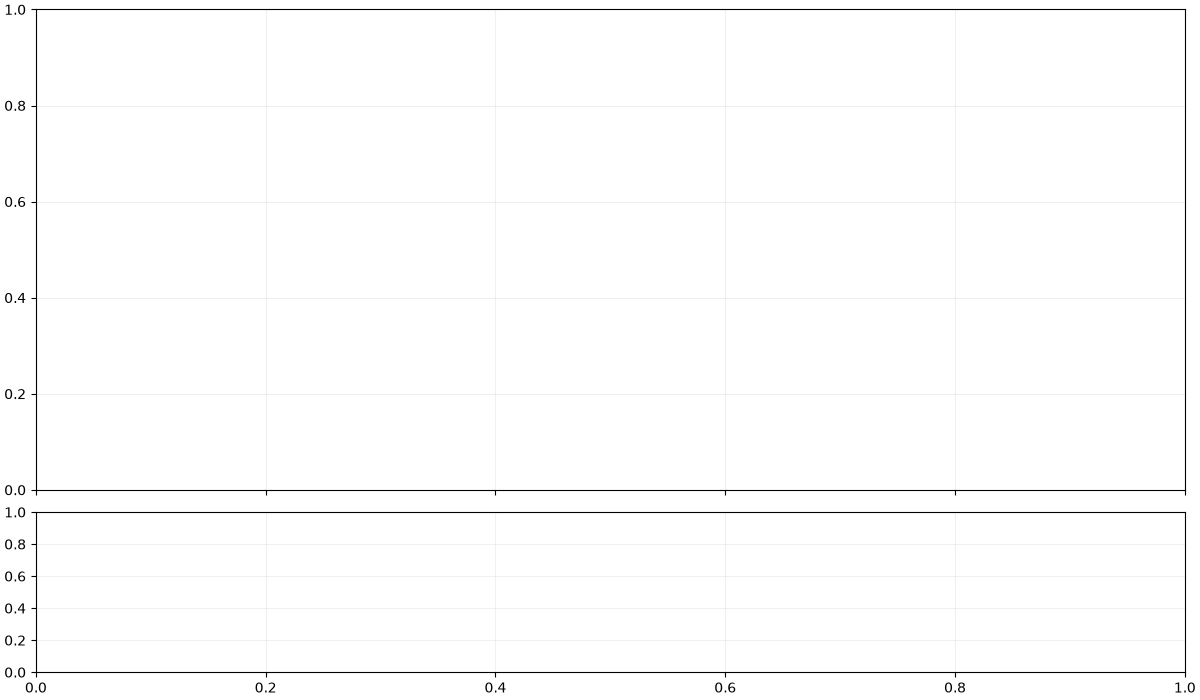

HTML(value='')

In [190]:
if temp_run.get('plot_task') is not None: temp_run['plot_task'].cancel()
if temp_run.get('figure') is not None: plt.close(temp_run['figure'])
with plt.ioff():
    temp_run['figure'], temp_run['axes'] = plt.subplots(2, 1, sharex=True, figsize=(12, 7),
        gridspec_kw={'height_ratios': [3, 1]}, layout='constrained')
temp_run['display_status'] = widgets.HTML()
display(temp_run['figure'].canvas, temp_run['display_status'])
temp_run['plot_task'] = asyncio.create_task(refresh_temperature_plot(temp_run))


### Change cadence while running

This cell changes only host sampling and plotting intervals; it does not rerun setup.


In [243]:
# Electrical diode + TEC output power; excludes driver losses and heater power.
laser_bank_milliwattage = pcb.laser_bank_power_mw(LOAD_LASERS)


In [ ]:
TEMP_POLL_INTERVAL_S = 10.
PLOT_REFRESH_INTERVAL_S = 180.


## Cold YJ darks — run when ready

Change RUN_DARK to True, then run this cell. YJ lasers must already be off; firmware enforces
10 continuous seconds of PD-on/lasers-off settling before each 2-second window. HK is looking at sky
and is excluded. Thermal logging continues, and YJ's prior PD power policy is restored even on error.

Accepted captures update the active dark with persist=False. Compare returned mean_mv / rms_mv
with initial_yj_dark in the capture context. A rejected capture clears pending but retains the old dark:
returned windows and observed failure warnings are saved, and pending=False alone does not prove a fresh dark.


In [41]:
RUN_DARK = True  # Lab expectation: YJ dark is probably around -1 mV.
DARK_REPEATS, DARK_DURATION_MS, DARK_GAP_S, DARK_TIMEOUT_S = 2, 2000, 30., 60.
if RUN_DARK:
    client = temp_run['client']
    previous_power = client.pd_settings('yj').power
    previous_phase = temp_run['phase']
    temp_run['phase'] = 'cold_dark_w_pd_prepowered'
    try:
        await asyncio.to_thread(client.pd_settings, 'yj', power='override_on', persist=False)
        for repeat in range(DARK_REPEATS):
            entry = dict(repeat=repeat+1, issue_utc_ms=time.time_ns()//1_000_000,
                requested_duration_ms=DARK_DURATION_MS, completion_observed=False, error='')
            before, dark = client.warnings, None
            try:
                dark = await asyncio.to_thread(client.pd_dark, 'yj', duration_ms=DARK_DURATION_MS, persist=False)
                deadline = time.monotonic() + DARK_TIMEOUT_S
                while dark.pending:
                    if time.monotonic() >= deadline:
                        raise TimeoutError('Dark still pending on board; inspect pd_dark("yj") and device log.')
                    await asyncio.sleep(.25)
                    dark = await asyncio.to_thread(client.pd_dark, 'yj')
                entry['completion_observed'] = True
                await asyncio.sleep(.5)  # Allow queued best-effort failure warnings to arrive.
            except Exception as exc:
                entry['error'] = str(exc)
                raise
            finally:
                entry['receipt_utc_ms'] = time.time_ns()//1_000_000
                if dark is not None: entry['response'] = asdict(dark)
                entry['warnings'] = [asdict(w) for w in client.warnings if w not in before]
                entry['failure_warning'] = any(w['code']=='photodiode_dark_failed' for w in entry['warnings'])
                with temp_run['lock']: temp_run['darks'].append(entry)
                checkpoint_temp(temp_run)
                display(pd.DataFrame([entry]))
            if repeat+1 < DARK_REPEATS: await asyncio.sleep(DARK_GAP_S)
    finally:
        try: await asyncio.to_thread(client.pd_settings, 'yj', power=previous_power, persist=False)
        finally:
            temp_run['phase'] = previous_phase
            checkpoint_temp(temp_run)


,repeat,issue_utc_ms,requested_duration_ms,completion_observed,error,receipt_utc_ms,response,warnings,failure_warning
0,1,1791405821251,2000,True,,1791405823878,"{'channel': 'yj', 'pending': False, 'duration_...",[],False


,repeat,issue_utc_ms,requested_duration_ms,completion_observed,error,receipt_utc_ms,response,warnings,failure_warning
0,2,1791405853905,2000,True,,1791405856525,"{'channel': 'yj', 'pending': False, 'duration_...",[],False


In [44]:
[(x['response']['dark']['mean_mv'],x['response']['lowest_dark']['mean_mv']) for x in  temp_run['darks']]

[(-2.47812509537, -2.496875),
 (-2.5078125, -2.5078125),
 (-2.50156259537, -2.5078125),
 (-2.55312490463, -2.55312490463),
 (-2.51718759537, -2.55312490463),
 (-2.5546875, -2.5546875)]

## High-power heat test — run when ready

Choose devices independently for later experiments, then change RUN_LOAD to True. Defaults drive all
six FVOA pairs and both PDs, and run five lasers at value=1 (nominal operating current). Leave 1430hk
and its TEC idle for the box probe. Laser auto-off is eight hours; PD overrides require manual shutdown.
The result table reports partial failures for human inspection; loads remain as commanded afterward.


In [210]:
RUN_LOAD = True
LOAD_LASERS = [n for n in hspcb.LASER_NAMES if n != '1430hk']
LOAD_FVOAS = list(hspcb.LASER_NAMES)
LOAD_PDS = ['yj', 'hk']
LOAD_AUTOOFF_S = 4 * 60 * 60
TEC_SETPOINT=18
if RUN_LOAD:
    client = temp_run['client']
    temp_run['phase'] = 'high_load_cooling'
    load_issue_utc_ms = time.time_ns()//1_000_000
    operations = [(f'{n} FVOAs 3000 mV', partial(client.atten, n, value1_mv=3000, value2_mv=3000)) for n in LOAD_FVOAS if n != '1510h' ]
    operations += [(f'{c} PD on', partial(client.pd_settings, c, power='override_on', persist=False)) for c in LOAD_PDS]
    operations += [(f'{n} laser tec setpoint', partial(client.laser_settings, n, default_operating_temp_c=TEC_SETPOINT)) for n in LOAD_LASERS]
    operations += [(f'{n} laser on', partial(client.laser, n, value=1., autooff_s=LOAD_AUTOOFF_S)) for n in LOAD_LASERS]
    load_results = []
    for operation, call in operations:
        try: load_results.append(dict(operation=operation, ok=True, result=asdict(call()), error=''))
        except Exception as exc: load_results.append(dict(operation=operation, ok=False, result=None, error=str(exc)))
    with temp_run['lock']: temp_run['context'].setdefault('load_steps', []).append(dict(
        issue_utc_ms=load_issue_utc_ms, receipt_utc_ms=time.time_ns()//1_000_000, lasers=list(LOAD_LASERS), fvoas=list(LOAD_FVOAS),
        pds=list(LOAD_PDS), autooff_s=LOAD_AUTOOFF_S, results=pd.DataFrame(load_results)))
    checkpoint_temp(temp_run)
    display(pd.DataFrame(load_results), status_snapshot(temp_run))


,operation,ok,result,error
0,1028y FVOAs 3000 mV,True,"{'db': 142.417366, 'linear': 5.73143534e-15, '...",
1,1270j FVOAs 3000 mV,True,"{'db': 117.754559, 'linear': 1.67704278938e-12...",
2,1430yj FVOAs 3000 mV,True,"{'db': 103.110443, 'linear': 4.88602504171e-11...",
3,1430hk FVOAs 3000 mV,True,"{'db': 106.040199, 'linear': 2.48874311753e-11...",
4,2330k FVOAs 3000 mV,True,"{'db': 106.040199, 'linear': 2.48874311753e-11...",
5,yj PD on,True,{'status': 'ok'},
6,hk PD on,True,{'status': 'ok'},
7,1028y laser tec setpoint,True,{'status': 'ok'},
8,1270j laser tec setpoint,True,{'status': 'ok'},
9,1430yj laser tec setpoint,True,{'status': 'ok'},


{'fw': '5dfd966e74a9-dirty',
 'boots': 115,
 'board': 'tib',
 'board_ok': True,
 'mems_switches': 8,
 'relay_err': 0,
 'amb_c': 9.625,
 'pd_on_s': 4805,
 'laserbank_on_s': 5201,
 'lastcmd': {'name': 'laser', 'src': 'mqtt', 't_ms': 111748528},
 'ip': None,
 'lasers': (),
 'attens': ()}

## Return to low power

Run this cell when you want the loads off. Monitoring continues.
This is the same deliberate low-power operation as startup.

All six laser endpoints receive stop=True; bank power/mode are preserved. Heater mode returns
to auto, and TEC shutdown follows existing channel settings. Failures remain visible in the table.


In [205]:
display(apply_low_power(temp_run), status_snapshot(temp_run))
checkpoint_temp(temp_run)


,operation,ok,result,error
0,throughput stop,True,{'status': 'ok'},
1,calibration stop,True,"{'state': 'inactive', 'mode': 'none', 'physica...",
2,bank off,True,"{'mode': 'override_off', 'powered': False}",
3,bank auto,True,"{'mode': 'auto', 'powered': False}",
4,1028y FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
5,1270j FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
6,1430yj FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
7,1430hk FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
8,1510h FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",
9,2330k FVOAs zero,True,"{'db': 0.0, 'linear': 1, 'v1_mv': 0.0, 'v2_mv'...",


{'fw': '5dfd966e74a9-dirty',
 'boots': 115,
 'board': 'tib',
 'board_ok': True,
 'mems_switches': 8,
 'relay_err': 0,
 'amb_c': 6.625,
 'pd_on_s': 0,
 'laserbank_on_s': 0,
 'lastcmd': {'name': 'laser/bankheater/auto',
  'src': 'mqtt',
  't_ms': 106536782},
 'ip': None,
 'lasers': (),
 'attens': ()}

## Stop and save — manual end of test

Change END_TEST to True to join the poll thread, cancel plot refresh, query final status, save all tables,
and restore the client's logger/callback. Hardware loads remain in their current state; run the preceding
cell first if you want low power. The client stays connected for further manual work.

Reload with pd.read_pickle(capture_file); its samples table is the complete thermal DataFrame.


In [172]:

final_capture = stop_temp_capture(temp_run)
draw_temperature_plot(temp_run) if temp_run.get('figure') is not None else None
print(f'Saved {final_capture}')
display(temp_data.tail(), pd.DataFrame(temp_run['darks']))


Saved /Users/jibailey/src/hispec-zephyr-mlang/hispec-tib/tools/temp_data/temp_20261007T190615_212906Z.pkl


,issue_utc_ms,receipt_utc_ms,elapsed_s,phase,poll_interval_s,mode,auto_state,heater_on,bank_power,ambient_c,...,probe_1430hk_c,probe_1510h_c,probe_2330k_c,pd_yj_mode,pd_yj_powered,pd_yj_on_s,pd_hk_mode,pd_hk_powered,pd_hk_on_s,error
2096,1791421049700,1791421049827,21074.512044,low_power,10.0,auto,warming_disabled_tec,True,True,-14.88,...,12.29,12.28,12.67,override_off,False,0,override_off,False,0,
2097,1791421059752,1791421059880,21084.564708,low_power,10.0,auto,warming_disabled_tec,True,True,-14.81,...,12.31,12.28,12.67,override_off,False,0,override_off,False,0,
2098,1791421069800,1791421069919,21094.604083,low_power,10.0,auto,warming_disabled_tec,True,True,-14.81,...,12.31,12.28,12.67,override_off,False,0,override_off,False,0,
2099,1791421079818,1791421079939,21104.624139,low_power,10.0,auto,warming_disabled_tec,True,True,-14.81,...,12.32,12.29,12.67,override_off,False,0,override_off,False,0,
2100,1791421085419,1791421085543,21110.227653,low_power,10.0,auto,warming_disabled_tec,True,True,-14.81,...,12.33,12.28,12.66,override_off,False,0,override_off,False,0,


,repeat,issue_utc_ms,requested_duration_ms,completion_observed,error,receipt_utc_ms,response,warnings,failure_warning
0,1,1791400361536,2000,True,,1791400374194,"{'channel': 'yj', 'pending': False, 'duration_...",[],False
1,2,1791400404213,2000,True,,1791400406820,"{'channel': 'yj', 'pending': False, 'duration_...",[],False
2,1,1791404354919,2000,True,,1791404367532,"{'channel': 'yj', 'pending': False, 'duration_...",[],False
3,2,1791404397553,2000,True,,1791404400189,"{'channel': 'yj', 'pending': False, 'duration_...",[],False
4,1,1791405821251,2000,True,,1791405823878,"{'channel': 'yj', 'pending': False, 'duration_...",[],False
5,2,1791405853905,2000,True,,1791405856525,"{'channel': 'yj', 'pending': False, 'duration_...",[],False


In [173]:
pcb.status()

Status(
  fw='5dfd966e74a9-dirty',
  boots=115,
  board='tib',
  board_ok=True,
  mems_switches=8,
  relay_err=0,
  amb_c=-14.812,
  pd_on_s=0,
  laserbank_on_s=780,
  lastcmd=LastCommand(name='laser/bankheater/auto', src='mqtt', t_ms=26486264),
  ip=None,
  lasers=(),
  attens=()
)